# 01 — Pulizia degli articoli

Dal dataset dello scraping (`0-scraping/costruisci_dataset.ipynb`: articoli in inglese, più di 100 parole,
senza doppioni di URL o di testo nella stessa testata) ad articoli puliti dagli **artefatti**: doppioni,
archivi vecchi, testo ripetuto della testata, cornice della pagina. La pulizia è **rigorosa ma non eccessiva**:
ciò che c'è in uno scenario reale (citazioni, pezzi ripresi da altri) resta; si toglie solo ciò che non è testo
dell'articolo o che metterebbe lo stesso testo nel training e nel test. Le etichette NewsGuard non si usano: si
tolgono appena caricato il dataset e tornano solo in `03_dataset_finale`.

| Passo | Cosa si toglie | Perché |
|---|---|---|
| 1 | copie esatte dentro la stessa testata (testo normalizzato) | lo stesso articolo contato due volte |
| 2 | niente: si **trovano** le copie (anche quasi esatte) tra testate diverse | servono a `02_reti` come prova di parentela; `03` toglie quelle tra gruppi diversi |
| 3 | articoli pubblicati prima di `DATA_MINIMA` | il giudizio NewsGuard è attuale; gli archivi vecchi portano argomenti d'epoca che non c'entrano con l'affidabilità |
| 4 | dentro i testi: le frasi ripetute in molti articoli della stessa testata | firme, biografie, promozioni, avvisi: testo della testata, non dell'articolo |
| 4b | la cornice della pagina all'inizio del testo: il titolo ripetuto e il timbro di pubblicazione | dipendono dal CMS del sito, non dall'articolo, e quindi riconoscono il sito |
| 4c | **(Versione 2)** i resti dei contenuti incorporati: link (`http…`, `www…`, `pic.twitter.com/…`), firme dei tweet incorporati ("— Nome (@utente) data"), righe che erano solo un link | sono pezzi della pagina, non testo dell'articolo; alcuni siti ne hanno molti di più, e un modello che conta le parole li usa per riconoscerli |
| 5 | doppioni dentro la stessa testata sul testo pulito (se ne tiene uno) | aggiornamenti e ripubblicazioni dello stesso pezzo |
| 6 | articoli rimasti con meno di `MIN_PAROLE` parole | non resta abbastanza testo |

Le citazioni e i paragrafi condivisi con altre testate restano: fanno parte di come si scrive una notizia.

**Sul server** (serve l'HTML grezzo, che sta solo lì):

```bash
cd ~/John/WebScience2027/Versione2/1-data-cleaning
screen -dmS cleaning papermill -k johnvenv 01_pulizia_articoli.ipynb ../Results/1-data-cleaning/esecuzioni/01_pulizia_articoli.ipynb
```

In [1]:
import collections
import hashlib
import os
import re

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from datasketch import MinHash, MinHashLSH
from joblib import Parallel, delayed

from comune import DERIVED, RESULTS, SEED, carica_articoli, frasi, normalizza

os.makedirs(DERIVED, exist_ok=True); os.makedirs(RESULTS, exist_ok=True)

In [2]:
DATA_MINIMA = "2025-01-01"
SOGLIA_COPIA = 0.5             # Jaccard dei 5-grammi di parole oltre il quale due articoli sono copie
RIPETIZIONI_IN_TESTATA = 3     # frasi ripetute in almeno tanti articoli della stessa testata: si tolgono
MIN_PAROLE = 100
N_JOBS = 32

In [3]:
art = carica_articoli().drop(columns=["label", "score"])      # cieco alle etichette
art["data"] = pd.to_datetime(art.data, errors="coerce")
art["norm"] = art.text.map(normalizza)
passi = []


def passo(nome, df):
    passi.append({"passo": nome, "articoli": len(df), "testate": df.domain.nunique()})
    print(f"{nome}: {len(df)} articoli, {df.domain.nunique()} testate")


passo("dataset dello scraping", art)

dataset dello scraping: 101887 articoli, 1046 testate


## 1. Copie esatte dentro la stessa testata

Testo normalizzato (minuscole, solo lettere e cifre): due articoli con la stessa impronta sono lo stesso
testo. Lo scraping toglieva già i doppioni identici carattere per carattere; qui si prendono anche quelli che
differiscono solo per punteggiatura o spazi. Si tiene il più vecchio.

In [4]:
art["impronta"] = art.norm.map(lambda s: hashlib.md5(s.encode()).hexdigest())
uguali = art.groupby("impronta").domain.agg(copie="size", testate="nunique")
print(f"articoli con una copia identica: nella stessa testata {((art.impronta.map(uguali.copie) > 1) & (art.impronta.map(uguali.testate) == 1)).sum()}, "
      f"in un'altra testata {(art.impronta.map(uguali.testate) > 1).sum()} (di questi si occupa 03)")
art = art.sort_values("data").drop_duplicates(["domain", "impronta"]).sort_index()
passo("1. senza copie esatte nella stessa testata", art)

articoli con una copia identica: nella stessa testata 32, in un'altra testata 16397 (di questi si occupa 03)
1. senza copie esatte nella stessa testata: 101869 articoli, 1046 testate


## 2. Copie tra testate diverse

MinHash (128 permutazioni) sui 5-grammi di parole del testo normalizzato, con LSH per trovare le coppie
candidate (Jaccard stimato da 0,3 in su). La distribuzione del Jaccard tra testate diverse è nettamente
bimodale: quasi tutte le coppie sono copie (≥ 0,9), pochissime stanno in mezzo. `SOGLIA_COPIA` = 0,5
(più di metà dei 5-grammi in comune) cade nel vuoto tra i due gruppi.

Qui le copie si **trovano soltanto**. Servono a `02_reti` (molte copie in comune = testate parenti), e
`03_dataset_finale` toglie quelle tra testate di **gruppi diversi**, che metterebbero lo stesso testo nel
training e nel test. Le copie dentro la stessa rete restano: è normale che una rete ripubblichi i propri pezzi,
e le sue testate stanno comunque dalla stessa parte. Le coppie si calcolano su tutti gli articoli, anche quelli
che il passo 3 toglierà per la data: una copia resta una copia.

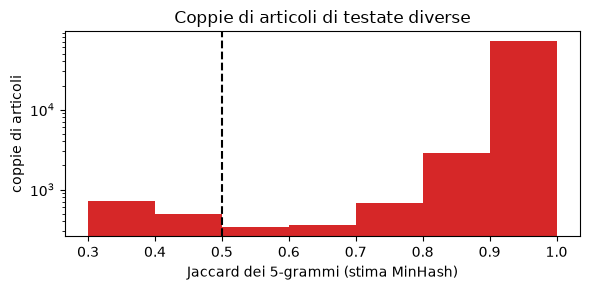

[722, 500, 338, 356, 677, 2861, 72907] coppie per fascia [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
articoli con una copia in un'altra testata: 25509 (25.0%); coppie salvate: 77139


In [5]:
def firma(testo):
    w = testo.split()
    m = MinHash(num_perm=128, seed=SEED)
    m.update_batch([" ".join(w[i:i + 5]).encode() for i in range(max(1, len(w) - 4))])
    return m


def coppie_simili(df, soglia_lsh):
    firme = Parallel(n_jobs=N_JOBS, batch_size=500)(delayed(firma)(t) for t in df.norm)
    lsh = MinHashLSH(threshold=soglia_lsh, num_perm=128)
    for i, m in enumerate(firme):
        lsh.insert(i, m)
    c = pd.DataFrame([(i, j, m.jaccard(firme[j])) for i, m in enumerate(firme) for j in lsh.query(m) if j > i],
                     columns=["i", "j", "jaccard"])
    for lato, col in [("a", "i"), ("b", "j")]:
        c[f"articolo_{lato}"] = df.article_id.values[c[col]]
        c[f"testata_{lato}"] = df.domain.values[c[col]]
    return c.drop(columns=["i", "j"])


coppie = coppie_simili(art.reset_index(drop=True), 0.3)
tra = coppie[coppie.testata_a != coppie.testata_b]
bins = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0001]
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(tra.jaccard, bins=bins, color="tab:red")
ax.axvline(SOGLIA_COPIA, color="k", ls="--"); ax.set_yscale("log")
ax.set_xlabel("Jaccard dei 5-grammi (stima MinHash)"); ax.set_ylabel("coppie di articoli")
ax.set_title("Coppie di articoli di testate diverse"); plt.tight_layout(); plt.show()
print(np.histogram(tra.jaccard, bins=bins)[0].tolist(), "coppie per fascia", bins[:-1])

copie = tra[tra.jaccard >= SOGLIA_COPIA]
copie.to_csv(DERIVED + "01_copie_tra_testate.csv", index=False)
con_copia = set(copie.articolo_a) | set(copie.articolo_b)
print(f"articoli con una copia in un'altra testata: {len(con_copia)} ({len(con_copia) / len(art):.1%}); coppie salvate: {len(copie)}")

## 3. Solo articoli recenti

Le date vengono dalla pagina dell'articolo (trafilatura). Lo scraping prende gli articoli più recenti, ma per
alcune testate la sitemap porta ad archivi di anni fa.

In [6]:
anno = art.data.dt.year
print("articoli per anno:", anno.value_counts().sort_index().loc[2015:].to_dict())
print("testate con la maggior parte degli articoli prima del", DATA_MINIMA, ":",
      (art.assign(vecchio=art.data < DATA_MINIMA).groupby("domain").vecchio.mean() > 0.5).sum())
art = art[art.data >= DATA_MINIMA]
passo(f"3. pubblicati dal {DATA_MINIMA}", art)

articoli per anno: {2015.0: 593, 2016.0: 654, 2017.0: 1032, 2018.0: 1499, 2019.0: 1817, 2020.0: 1637, 2021.0: 1674, 2022.0: 2481, 2023.0: 2349, 2024.0: 4573, 2025.0: 5293, 2026.0: 74521}


testate con la maggior parte degli articoli prima del 2025-01-01 : 242


3. pubblicati dal 2025-01-01: 79814 articoli, 965 testate


## 4. Testo che non è dell'articolo

Si spezza ogni testo in righe e ogni riga in frasi. Una frase di qualsiasi lunghezza che compare in almeno
`RIPETIZIONI_IN_TESTATA` articoli **della stessa testata** si toglie: firme e biografie, promozioni, inviti a
iscriversi, "View all posts", liste "x days ago". È testo della testata, non dell'articolo, e permette a un
modello di riconoscere la testata a memoria invece di leggere l'articolo.

Le frasi si contano su tutti gli articoli rimasti dopo il passo 1 (anche quelli vecchi o copiati, che danno
più prove di cosa è ripetitivo). Una frase ripetuta in soli due articoli della stessa testata resta: può essere
lo stesso pezzo aggiornato, e se ne occupa il passo 5.

In [7]:
tutti = carica_articoli().drop(columns=["label", "score"])
tutti["norm"] = tutti.text.map(normalizza)
tutti = tutti.drop_duplicates(["domain", "norm"])
in_testata = collections.Counter()
for d, t in zip(tutti.domain, tutti.text):
    in_testata.update((d, f) for f in {normalizza(f) for riga in t.split("\n") for f in frasi(riga)} - {""})


def via(d, f):
    if in_testata[(d, f)] >= RIPETIZIONI_IN_TESTATA:
        return "ripetuta nella testata"
    return None


tolte = collections.Counter()


def pulisci(d, testo):
    righe = []
    for riga in testo.split("\n"):
        tenute = []
        for f in frasi(riga):
            perche = via(d, normalizza(f))
            if perche:
                tolte[perche] += len(f.split())
            else:
                tenute.append(f)
        if tenute:
            righe.append(" ".join(tenute))
    return "\n".join(righe)


parole_prima = art.text.str.split().str.len()
art["text"] = [pulisci(d, t) for d, t in zip(art.domain, art.text)]
art["norm"] = art.text.map(normalizza)
parole_dopo = art.text.str.split().str.len()
print(f"parole tolte: {1 - parole_dopo.sum() / parole_prima.sum():.1%} del totale; "
      + ", ".join(f"{k} {v / parole_prima.sum():.1%}" for k, v in tolte.items()))
quota = (1 - parole_dopo.groupby(art.domain).sum() / parole_prima.groupby(art.domain).sum()).sort_values(ascending=False)
quota.rename("quota di parole tolte").to_csv(RESULTS + "01_testo_tolto_per_testata.csv")
print("testate a cui si toglie di più:", quota.head(8).round(2).to_dict())

parole tolte: 5.2% del totale; ripetuta nella testata 5.2%
testate a cui si toglie di più: {'brexitnews.tv': 0.92, 'paine.tv': 0.88, 'ho1.us': 0.88, 'thenationalpulse.com': 0.85, 'newsbreak.com': 0.8, 'wiesbadener-kurier.de': 0.75, 'allgemeine-zeitung.de': 0.74, 'conservativewoman.co.uk': 0.72}


In [8]:
# esempi: le frasi tolte più spesso
ripetute = sorted(((n, d, f) for (d, f), n in in_testata.items() if n >= RIPETIZIONI_IN_TESTATA), reverse=True)
print("ripetute nella stessa testata (articoli, testata, frase):")
for n, d, f in ripetute[:10]:
    print(f"  {n:4d}  {d:28s} {f[:90]}")

ripetute nella stessa testata (articoli, testata, frase):
   200  truthout.org                 we lost 15 percent of our readership overnight
   200  truthout.org                 we are fundraising right now to meet our basic operating expenses
   200  truthout.org                 truthout is one of only a few platforms for justice oriented grassroots journalism
   200  truthout.org                 today we face an existential threat
   200  truthout.org                 this was a readership we painstakingly built over decades and it vanished because google c
   200  truthout.org                 if you can support truthout with a one time or monthly donation you will make a significan
   200  truthout.org                 due to google s launch of ai search we ve seen a drastic plunge in our site traffic and as
   200  truthout.org                 anything you can do makes a difference we appreciate your support
   200  truthout.org                 an urgent fundraising appeal 9 days to

## 4b. La cornice della pagina

Il testo estratto da trafilatura a volte comincia con il titolo dell'articolo e con il timbro di
pubblicazione ("Published 2:00 pm Saturday, September 26, 2026"). Succede per alcuni CMS e non per altri:
è un'impronta del sito, non testo dell'articolo. Si tolgono il titolo (anche senza il nome del sito che a
volte lo segue, "… – The Horn News") e un timbro di data/ora all'inizio del testo.

In [9]:
MESI = r"(?:January|February|March|April|May|June|July|August|September|October|November|December|Jan|Feb|Mar|Apr|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)\.?"
ORA = r"\d{1,2}:\d\d\s*(?:[ap]\.?m\.?)?(?:\s*[A-Z]{2,4}T)?"
TIMBRO = re.compile(rf"^\s*(?:(?:Published|Updated|Posted|Last updated)\s*(?:on|at)?\s*)?(?:{ORA}\s*)?(?:\w+day,?\s*)?"
                    rf"{MESI}\s+\d{{1,2}},?\s+20\d\d(?:\s*(?:at|,)?\s*{ORA})?[\s|·•,-]*", re.I)


def togli_cornice(testo, titolo):
    fine_parole = [m.end() for m in re.finditer(r"\S+", testo)]     # dove finisce ogni parola (a capo compresi)
    taglio, tolto = 0, None
    candidati = {normalizza(titolo), normalizza(re.split(r"\s[-–—|]\s", str(titolo))[0])}
    for cand in sorted((c for c in candidati if len(c.split()) >= 3), key=len, reverse=True):
        n = len(cand.split())
        for k in range(max(1, n - 4), min(n + 6, len(fine_parole)) + 1):     # la punteggiatura cambia il numero di parole
            if normalizza(testo[:fine_parole[k - 1]]) == cand:
                taglio, tolto = fine_parole[k - 1], "titolo"; break
        if tolto:
            break
    resto = testo[taglio:].lstrip()
    senza_timbro = TIMBRO.sub("", resto, count=1)
    return senza_timbro, tolto, senza_timbro != resto


esiti = [togli_cornice(t, ti) for t, ti in zip(art.text, art.titolo.fillna(""))]
art["text"] = [e[0] for e in esiti]
art["norm"] = art.text.map(normalizza)
print(f"titolo tolto dall'inizio: {sum(e[1] == 'titolo' for e in esiti)} articoli; timbro tolto: {sum(e[2] for e in esiti)} articoli")

titolo tolto dall'inizio: 22641 articoli; timbro tolto: 3919 articoli


## 4c. I resti dei contenuti incorporati (Versione 2)

Quando una pagina incorpora un tweet, un video o un post, l'estrazione lascia nel testo dei resti: il link
`pic.twitter.com/…`, la firma del tweet ("— Nome (@utente) 23 settembre 2026"), link nudi `https://…` e `www.…`,
righe che erano solo un link ("Instagram: www.instagram.com/…"). Non sono testo dell'articolo, e nella prima
versione il classificatore a feature li usava (le parole *pic twitter*, *https*, *www* erano tra le più forti
verso $l_1$). Regole fisse, uguali per tutte le testate:

- si tolgono i link (`http…`, `www.…`, `pic.twitter.com/…`), lasciando il resto della riga;
- si toglie la firma di un tweet incorporato in fondo alla riga ("… — Nome (@utente) data"): il testo del tweet,
  che è una citazione, resta; si tolgono le righe che sono solo una firma ("Nome (@utente) data") e la scritta fissa
  dei post incorporati ("View this post on Instagram", "A post shared by…");
- si tolgono le righe che, senza il link, restano con meno di `MIN_PAROLE_RIGA` parole.

Le menzioni `@utente` dentro le frasi e i nomi di siti citati ("ha detto a 7NEWS.com.au") restano: sono testo.

In [10]:
MIN_PAROLE_RIGA = 3
LINK = re.compile(r"(?:https?://|www\.)\S+|pic\.twitter\.com/\S+", re.I)
DATA_TWEET = rf"{MESI}\s+\d{{1,2}},?\s+\d{{4}}"
# la firma di un tweet incorporato in fondo alla riga: "… — Nome (@utente) 29 giugno 2026" (si toglie solo la firma)
FIRMA_IN_FONDO = re.compile(rf"(?:[—–]{{1,2}}|\s-{{1,2}})\s*[^—–\n]{{0,80}}\(@\w{{1,30}}\)\s*(?:{DATA_TWEET})?\s*$", re.I)
# una riga che è solo la firma, senza trattino: "Nome (@utente) 29 giugno 2026"
FIRMA_SOLA = re.compile(rf"^\s*[^\n]{{0,80}}\(@\w{{1,30}}\)\s*{DATA_TWEET}\s*$", re.I)
SCRITTE_INCORPORATI = re.compile(r"^\s*(?:View this post on Instagram|A post shared by [^\n]{0,80})\s*$", re.I)


def togli_incorporati(testo):
    righe, conta = [], collections.Counter()
    for riga in testo.split("\n"):
        if FIRMA_SOLA.match(riga) or SCRITTE_INCORPORATI.match(riga):
            conta["righe di firma o scritte di contenuti incorporati"] += 1
            continue
        nuova, f = FIRMA_IN_FONDO.subn("", riga)
        nuova, k = LINK.subn("", nuova)
        if f:
            conta["firme di tweet in fondo alla riga"] += 1
        if k:
            conta["link"] += k
        if (f or k) and len(re.findall(r"[^\W\d_]{2,}", nuova)) < MIN_PAROLE_RIGA:
            conta["righe rimaste quasi vuote"] += 1
            continue
        righe.append(re.sub(r"[ \t]{2,}", " ", nuova).strip() if (f or k) else riga)
    return "\n".join(righe), conta


esiti = [togli_incorporati(t) for t in art.text]
art["text"] = [e[0] for e in esiti]
art["norm"] = art.text.map(normalizza)
totale = sum((e[1] for e in esiti), collections.Counter())
print(f"articoli toccati: {sum(bool(e[1]) for e in esiti)} su {len(art)}; " + ", ".join(f"{k} {v}" for k, v in totale.items()))
esempi = [(r, togli_incorporati(r)[0]) for t in carica_articoli().text.head(20000).fillna("") for r in t.split("\n")
          if FIRMA_IN_FONDO.search(r) or FIRMA_SOLA.match(r)][:6]
print("esempi (prima -> dopo):")
for a, b in esempi:
    print(f"  {a[:110]!r}\n   -> {b[:110]!r}")

articoli toccati: 9313 su 79814; link 20359, righe rimaste quasi vuote 3632, righe di firma o scritte di contenuti incorporati 16212, firme di tweet in fondo alla riga 122


esempi (prima -> dopo):
  '— Paul Peeters (@palpeet) September 11, 2026'
   -> ''
  '— Angela Bassett Archives (@ABassettArchive) September 23, 2026'
   -> ''
  '— The Stanford Review (@StanfordReview) September 21, 2026'
   -> ''
  '— Jacob Coxon (@hilbertspaess) September 9, 2026'
   -> ''
  '— Cardi B (@iamcardib) September 1, 2026'
   -> ''
  '— SBA (@SBAgov) September 26, 2023'
   -> ''


## 5. Doppioni dentro la stessa testata, sul testo pulito

Tolte le parti ripetute, due articoli della stessa testata con Jaccard ≥ `SOGLIA_COPIA` sono lo stesso
pezzo (aggiornato o ripubblicato): se ne tiene uno, il più vecchio.

In [11]:
art = art.reset_index(drop=True)
dentro = coppie_simili(art, SOGLIA_COPIA)
dentro = dentro[(dentro.testata_a == dentro.testata_b) & (dentro.jaccard >= SOGLIA_COPIA)]
G = nx.Graph(); G.add_edges_from(zip(dentro.articolo_a, dentro.articolo_b))
data = art.set_index("article_id").data
via_doppi = {x for fam in nx.connected_components(G) for x in sorted(fam, key=lambda x: (data[x], x))[1:]}
print(f"famiglie di doppioni: {nx.number_connected_components(G)}, articoli tolti: {len(via_doppi)}")
art = art[~art.article_id.isin(via_doppi)]
passo("5. senza doppioni nella stessa testata", art)

famiglie di doppioni: 202, articoli tolti: 465
5. senza doppioni nella stessa testata: 79349 articoli, 965 testate


## 6. Abbastanza testo

In [12]:
art = art[art.text.str.split().str.len() >= MIN_PAROLE]
passo(f"6. almeno {MIN_PAROLE} parole", art)

6. almeno 100 parole: 76072 articoli, 963 testate


## Riepilogo e salvataggio

Tutte le testate, anche quelle rimaste con pochi articoli: il minimo per testata si applica in
`03_dataset_finale`.

In [13]:
passi = pd.DataFrame(passi).set_index("passo")
passi.to_csv(RESULTS + "01_passi.csv")
display(passi)
n = art.groupby("domain").size()
print(f"testate con almeno 10 articoli: {(n >= 10).sum()}, con almeno 20: {(n >= 20).sum()}")
art[["article_id", "domain", "url", "titolo", "data", "autore", "text"]].to_csv(DERIVED + "01_articoli_puliti.csv", index=False)

,articoli,testate
passo,,
dataset dello scraping,101887,1046
1. senza copie esatte nella stessa testata,101869,1046
3. pubblicati dal 2025-01-01,79814,965
5. senza doppioni nella stessa testata,79349,965
6. almeno 100 parole,76072,963


testate con almeno 10 articoli: 822, con almeno 20: 703
